# Q1 Maize Yield Preparation

This notebook contains the complete workflow. Each stage begins with an explanation before its code. Run the stages from top to bottom in a clean kernel.

## Step 1 — Verify the environment

The explanation below describes this step before the code runs.

Group Achille-Sylvie | Members: Cishahayo Songa Achille, Umwiza Sylvie | Question: Q1 | Stage: 1: environment test

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import platform, pandas as pd, numpy as np, sklearn, joblib
print('Python:', platform.python_version())
print('pandas:', pd.__version__, 'numpy:', np.__version__, 'scikit-learn:', sklearn.__version__, 'joblib:', joblib.__version__)


Python: 3.14.6
pandas: 3.0.3 numpy: 2.4.6 scikit-learn: 1.9.0 joblib: 1.5.3


## Step 2 — Acquire and document the revised dataset

The explanation below describes this step before the code runs.

This notebook documents the Rwanda maize source. The raw file is preserved unchanged; the cleaning stage derives model fields and converts tonnes/ha to kg/ha.

In [2]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import pandas as pd
from src.config import RAW_FILE, DOCS_DIR, COLUMNS
from src.cleaning import sha256_file, to_string_df

DOCS_DIR.mkdir(parents=True, exist_ok=True)
if not RAW_FILE.exists():
    raise FileNotFoundError(f'Revised Q1 raw file not found: {RAW_FILE}')
df_raw = to_string_df(RAW_FILE)
print('Using file:', RAW_FILE)
print('SHA-256:', sha256_file(RAW_FILE))
print('shape:', df_raw.shape)
display(df_raw.head())
display(df_raw.dtypes.rename('dtype').to_frame())

meta = {
 'record_id': ('Observation identifier','string','unique record code','No'),
 'year': ('Observation year','integer','2015-2030','No'),
 'season': ('Cropping season','category','A/B/C','No'),
 'province': ('Province','category','Rwanda province','No'),
 'district': ('District','category','Rwanda district','No'),
 'altitude_m': ('Altitude','numeric','metres','No'),
 'rainfall_mm': ('Rainfall','numeric','millimetres','No'),
 'avg_temp_c': ('Average temperature','numeric','degrees Celsius','No'),
 'soil_ph': ('Soil acidity','numeric','pH','No'),
 'soil_type': ('Soil category','category','soil class','No'),
 'seed_variety': ('Seed variety','category','variety label','No'),
 'farming_practice': ('Farming practice','category','Traditional/Improved','No'),
 'npk_kg_ha': ('NPK fertiliser','numeric','kg/ha','No'),
 'urea_kg_ha': ('Urea fertiliser','numeric','kg/ha','No'),
 'manure_t_ha': ('Manure','numeric','tonnes/ha','No'),
 'plant_density_per_ha': ('Plant density','numeric','plants/ha','No'),
 'farm_area_ha': ('Farm area','numeric','hectares','No'),
 'irrigation': ('Irrigation','category','Yes/No','No'),
 'pest_incidence_index': ('Pest incidence index','numeric','0-1 index','No'),
 'yield_t_ha': ('Yield target','numeric','tonnes/ha; converted to kg/ha','Yes'),
}
dd = pd.DataFrame([{'column_name': c, 'meaning': meta.get(c, ('','','',''))[0],
                    'data_type': meta.get(c, ('','','',''))[1],
                    'unit': meta.get(c, ('','','',''))[2],
                    'post_harvest_or_target': meta.get(c, ('','','',''))[3]} for c in COLUMNS])
dd.to_csv(DOCS_DIR / 'data_dictionary.csv', index=False)
(DOCS_DIR / 'data_dictionary.md').write_text('# Q1 Data Dictionary\n\n' + dd.to_string(index=False))
(DOCS_DIR / 'data_requirements.md').write_text('''# Q1 Data Requirements

- Target: `yield_t_ha`, converted to `yield_kg_per_ha` for modelling.
- Pre-harvest predictors: weather, altitude, soil, seed, farming practice, fertiliser, density, area, irrigation and pest index.
- The source contains 1,426 records and 20 columns, with missing rainfall, soil pH and pest-index values handled during preprocessing.
''')
(DOCS_DIR / 'source_log.md').write_text(f'''# Source Log

- File used: `{RAW_FILE.name}`
- SHA-256: `{sha256_file(RAW_FILE)}`
- Date accessed: {date.today().isoformat()}
- Source description: Rwanda maize yield records supplied for the revised Q1 dataset.
- Limitation: provenance and licence details should be completed from the dataset provider before submission.
''')


Using file: /home/songa/Documents/CODING/CLASS WORK/ML-Learning/q1_maize_yield/data/raw/maize_yield_rwanda_rw.csv
SHA-256: 2a81e0267334b477b740093859e1d0d0555996035b3169672ce774278b620576
shape: (1426, 20)


,record_id,year,season,province,district,altitude_m,rainfall_mm,avg_temp_c,soil_ph,soil_type,seed_variety,farming_practice,npk_kg_ha,urea_kg_ha,manure_t_ha,plant_density_per_ha,farm_area_ha,irrigation,pest_incidence_index,yield_t_ha
0,RW-MZ-00001,2015,A,Eastern,Bugesera,1349,,22.9,,Clay,RHM104,Improved,117.8,57.4,1.41,61803,0.63,No,,2.71
1,RW-MZ-00002,2015,A,Eastern,Bugesera,1427,489.8,22.1,6.02,Volcanic,RHM104,Improved,38.1,62.7,3.69,52919,0.17,No,0.339,4.09
2,RW-MZ-00003,2015,A,Northern,Burera,2033,722.6,16.3,5.73,Clay loam,Local,Improved,121.1,50.7,5.18,54406,0.22,No,0.049,2.58
3,RW-MZ-00004,2015,A,Northern,Burera,2026,794.4,16.4,5.2,Clay loam,ZM621,Improved,93.7,60.4,1.68,48119,0.48,No,0.171,2.45
4,RW-MZ-00005,2015,A,Northern,Gakenke,1974,644.2,18.3,5.92,Loam,Local,Improved,84.1,70.4,0.36,56787,1.16,No,0.001,2.09


,dtype
record_id,str
year,str
season,str
province,str
district,str
altitude_m,str
rainfall_mm,str
avg_temp_c,str
soil_ph,str
soil_type,str


357

## Step 3 — Explore and audit data quality

The explanation below describes this step before the code runs.

This notebook audits the schema without modifying the raw file, quantifies missingness and duplicates, and creates concise quality charts.

,problem,columns_affected,records_affected,severity,proposed_treatment
0,Exact duplicate rows,all,0,High,Remove exact duplicates
1,Repeated record identifiers,record_id,0,High,Keep the most complete record
2,Missing values,"rainfall_mm,soil_ph,pest_incidence_index",0,Medium,Fit training-only imputers
3,Invalid target or area,"yield_t_ha,farm_area_ha",0,High,Set invalid values missing and drop missing ta...
4,Out-of-range pest index,pest_incidence_index,0,Medium,Set invalid values missing
5,Potential target leakage,yield_t_ha,1426,High,Keep only as target; never include it in X


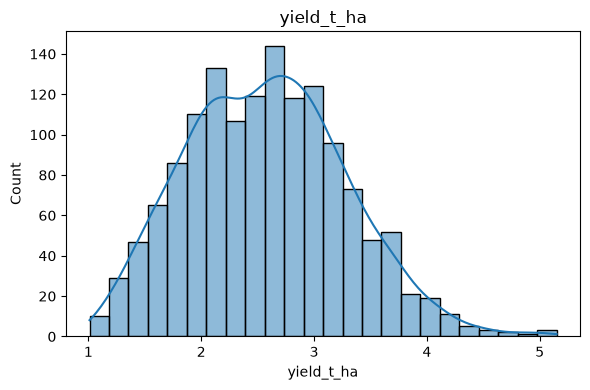

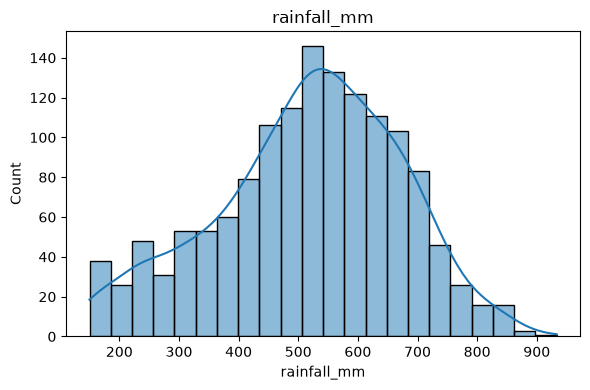

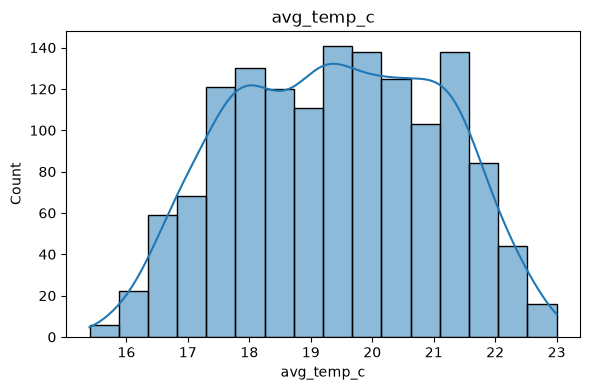

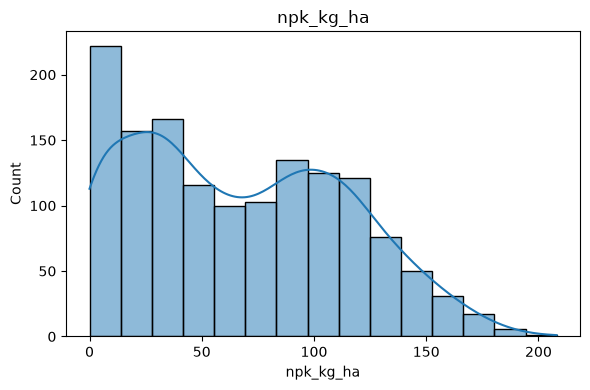

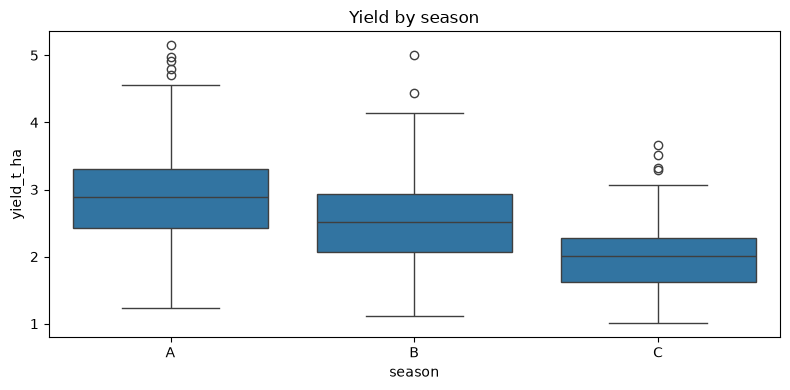

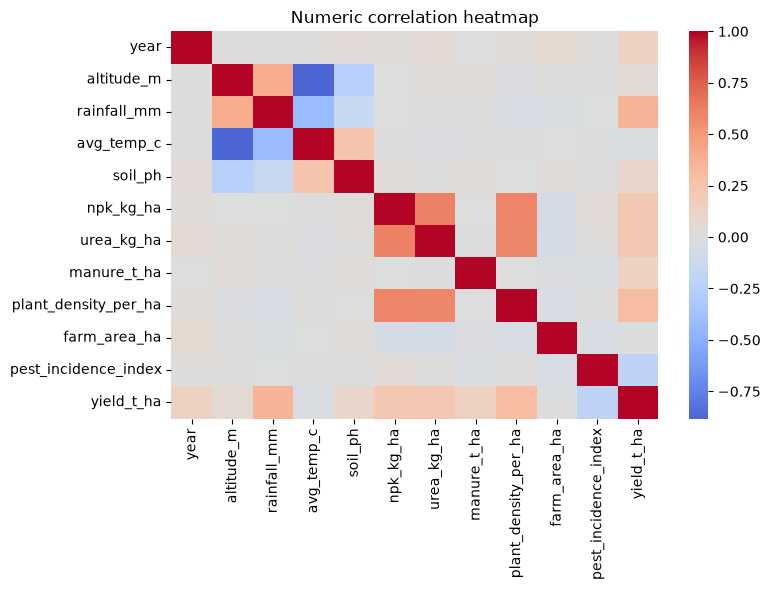

In [3]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt
from src.config import RAW_FILE, DOCS_DIR, FIGURE_DIR
from src.cleaning import to_string_df, parse_number
DOCS_DIR.mkdir(parents=True, exist_ok=True); FIGURE_DIR.mkdir(parents=True, exist_ok=True)
df = to_string_df(RAW_FILE)
issues = []
def add(problem, columns, count, severity, treatment):
    issues.append({'problem': problem, 'columns_affected': columns, 'records_affected': int(count), 'severity': severity, 'proposed_treatment': treatment})
add('Exact duplicate rows', 'all', df.duplicated().sum(), 'High', 'Remove exact duplicates')
add('Repeated record identifiers', 'record_id', df['record_id'].duplicated().sum(), 'High', 'Keep the most complete record')
add('Missing values', 'rainfall_mm,soil_ph,pest_incidence_index', df.isna().sum().sum(), 'Medium', 'Fit training-only imputers')
add('Invalid target or area', 'yield_t_ha,farm_area_ha', ((parse_number(df['yield_t_ha']) <= 0) | (parse_number(df['farm_area_ha']) <= 0)).sum(), 'High', 'Set invalid values missing and drop missing targets')
add('Out-of-range pest index', 'pest_incidence_index', ((parse_number(df['pest_incidence_index']) < 0) | (parse_number(df['pest_incidence_index']) > 1)).sum(), 'Medium', 'Set invalid values missing')
add('Potential target leakage', 'yield_t_ha', df['yield_t_ha'].notna().sum(), 'High', 'Keep only as target; never include it in X')
quality = pd.DataFrame(issues)
quality.to_csv(DOCS_DIR / 'data_quality_report.csv', index=False)
(DOCS_DIR / 'data_quality_report.md').write_text('# Q1 Data Quality Report\n\n' + quality.to_string(index=False))
display(quality)
for col in ['yield_t_ha','rainfall_mm','avg_temp_c','npk_kg_ha']:
    plt.figure(figsize=(6,4)); sns.histplot(parse_number(df[col]), kde=True); plt.title(col); plt.tight_layout(); plt.savefig(FIGURE_DIR / f'hist_{col}.png'); display(plt.gcf()); plt.close()
plt.figure(figsize=(8,4)); sns.boxplot(data=df, x='season', y=parse_number(df['yield_t_ha'])); plt.title('Yield by season'); plt.tight_layout(); plt.savefig(FIGURE_DIR / 'box_yield_season.png'); display(plt.gcf()); plt.close()
numeric = pd.DataFrame({c: parse_number(df[c]) for c in ['year','altitude_m','rainfall_mm','avg_temp_c','soil_ph','npk_kg_ha','urea_kg_ha','manure_t_ha','plant_density_per_ha','farm_area_ha','pest_incidence_index','yield_t_ha']})
plt.figure(figsize=(8,6)); sns.heatmap(numeric.corr(), cmap='coolwarm', center=0); plt.title('Numeric correlation heatmap'); plt.tight_layout(); plt.savefig(FIGURE_DIR / 'heatmap_corr.png'); display(plt.gcf()); plt.close()


## Step 4 — Clean and preprocess

The explanation below describes this step before the code runs.

Clean source values, derive canonical units, split by season, and fit preprocessing only on the training partition.

In [4]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd, joblib
from src.config import RAW_FILE, INTERIM_DIR, PROCESSED_DIR, DOCS_DIR, TARGET_COL
from src.cleaning import to_string_df, clean_q1, add_time_features
from src.features import engineer_features
from src.logging_utils import CleaningLog
from src.pipeline import split_train_val_test, build_preprocessor, transform_split, add_low_yield_label
for p in [INTERIM_DIR, PROCESSED_DIR, DOCS_DIR]: p.mkdir(parents=True, exist_ok=True)
clog = CleaningLog()
clean = engineer_features(add_time_features(clean_q1(to_string_df(RAW_FILE), clog)))
clean.to_csv(INTERIM_DIR / 'maize_clean.csv', index=False)
train_df, val_df, test_df = split_train_val_test(clean)
q20 = add_low_yield_label(train_df, val_df, test_df)
pre, feature_cols = build_preprocessor(train_df)
joblib.dump({'preprocessor': pre, 'feature_cols': feature_cols, 'q20_threshold': q20}, PROCESSED_DIR / 'preprocessor.joblib')
for src, name in [(train_df,'train'), (val_df,'validation'), (test_df,'test')]:
    X = transform_split(pre, src, feature_cols)
    pd.concat([src[['record_id', TARGET_COL, 'low_yield_risk']].reset_index(drop=True), X.reset_index(drop=True)], axis=1).to_csv(PROCESSED_DIR / f'{name}_model_ready.csv', index=False)
    src.to_csv(PROCESSED_DIR / f'{name}_clean_unscaled.csv', index=False)
clog.save(DOCS_DIR / 'cleaning_log.csv', DOCS_DIR / 'cleaning_log.md')
print('Split shapes:', train_df.shape, val_df.shape, test_df.shape)


Split shapes: (998, 38) (214, 38) (214, 38)


## Step 5 — Engineer and select features

The explanation below describes this step before the code runs.

Review dataset features using training data only; the target and source target column never enter the candidate inputs.

In [5]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from sklearn.feature_selection import mutual_info_regression
from src.config import PROCESSED_DIR, DOCS_DIR, TARGET_COL
from src.features import remove_high_corr, rf_importance, select_features_numeric
DOCS_DIR.mkdir(parents=True, exist_ok=True)
train = pd.read_csv(PROCESSED_DIR / 'train_clean_unscaled.csv')
excluded = {'record_id', TARGET_COL, 'yield_t_ha'}
X = train[[c for c in train.columns if c not in excluded]]
num = X.select_dtypes(include='number')
kept, selected = select_features_numeric(num, train[TARGET_COL], k=15)
mi = mutual_info_regression(num.fillna(num.median()), train[TARGET_COL], random_state=42)
mi_df = pd.DataFrame({'feature': num.columns, 'mutual_info': mi}).sort_values('mutual_info', ascending=False)
mi_df.to_csv(DOCS_DIR / 'mutual_information.csv', index=False)
rf_importance(X, train[TARGET_COL]).to_csv(DOCS_DIR / 'rf_importance.csv', index=False)
pd.DataFrame({'variance_kept': pd.Series(kept), 'selected_by_f_regression': pd.Series(selected)}).to_csv(DOCS_DIR / 'feature_selection.csv', index=False)
display(mi_df.head(15))


,feature,mutual_info
23,low_yield_risk,0.493111
18,rain_per_temp,0.116546
13,rainfall_per_temp,0.116469
19,rainfall_log,0.086698
2,rainfall_mm,0.081572
5,npk_kg_ha,0.063914
8,plant_density_per_ha,0.052337
3,avg_temp_c,0.040334
6,urea_kg_ha,0.035476
10,pest_incidence_index,0.032088


## Step 6 — Finalise and verify outputs

The explanation below describes this step before the code runs.

Package the revised Q1 outputs and document the new target, source fields, cleaning decisions, and limitations.

In [6]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
from src.config import DOCS_DIR, PROCESSED_DIR, TARGET_COL
from src.cleaning import to_string_df
import pandas as pd
train = pd.read_csv(PROCESSED_DIR / 'train_model_ready.csv')
val = pd.read_csv(PROCESSED_DIR / 'validation_model_ready.csv')
test = pd.read_csv(PROCESSED_DIR / 'test_model_ready.csv')
summary = f'''# Q1 Data Card

- Target: `{TARGET_COL}` (derived from source `yield_t_ha` by multiplying by 1,000).
- Records: train={len(train)}, validation={len(val)}, test={len(test)}.
- Revised source fields: record ID, year, season, geography, weather, soil, seed, farming practice, fertiliser, density, area, irrigation and pest index.
- Leakage control: `yield_t_ha` is excluded from model features; no harvest-weight field is present in the revised source.
- Prepared: {date.today().isoformat()}.
- Limitation: this is a prepared dataset, not a trained or deployed prediction model.
'''
(DOCS_DIR / 'data_card.md').write_text(summary)
(DOCS_DIR / 'memo_to_manager.md').write_text('''# Memo to Manager

The revised Rwanda maize dataset contains 1,426 observations and 20 source columns. The Q1 workflow now uses `yield_t_ha` as the target and converts it to `yield_kg_per_ha`. It derives total fertiliser from NPK, urea and manure, uses `farm_area_ha`, and maps the pest index into an ordinal category. Missing values are handled by training-fitted preprocessing, and the source target is excluded from model inputs. The outputs are ready for later model evaluation, but this repository still does not train a production model.
''')
print(summary)


# Q1 Data Card

- Target: `yield_kg_per_ha` (derived from source `yield_t_ha` by multiplying by 1,000).
- Records: train=998, validation=214, test=214.
- Revised source fields: record ID, year, season, geography, weather, soil, seed, farming practice, fertiliser, density, area, irrigation and pest index.
- Leakage control: `yield_t_ha` is excluded from model features; no harvest-weight field is present in the revised source.
- Prepared: 2026-11-12.
- Limitation: this is a prepared dataset, not a trained or deployed prediction model.

